# A tour of tpt-ml-proven

The estimators are compiled from Rust. Each one fits on a NumPy array (or a pandas frame), predicts or transforms, and saves to a model file that the Rust crates can also read. This notebook runs each part on small synthetic data.

Install the package from a build (`maturin develop` in `ffi/python`); it is not on PyPI yet.

In [1]:
import tempfile
import numpy as np
import pandas as pd

from tpt_ml_proven import KMeans, DBSCAN, DecisionTreeClassifier, RandomForestClassifier, StandardScaler, Ridge

rng = np.random.default_rng(0)
centres = np.array([[0.0, 0.0], [5.0, 5.0], [0.0, 6.0]])
X = np.vstack([c + 0.6 * rng.standard_normal((40, 2)) for c in centres])
frame = pd.DataFrame(X, columns=['x', 'y'])  # pandas frames are accepted directly
print(frame.shape, frame.head(3).round(2).to_string(index=False))

(120, 2)     x     y
 0.08 -0.08
 0.38  0.06
-0.32  0.22


## Clustering

KMeans returns labels as a NumPy array. `fit_predict` is fit followed by predict.

In [2]:
labels = KMeans(3, seed=1).fit_predict(frame)
print(type(labels).__name__, np.bincount(labels))

noise = DBSCAN(eps=0.9, min_samples=5).fit_predict(X)
print('DBSCAN clusters:', sorted(set(noise.tolist())), 'noise points:', int((noise == -1).sum()))

ndarray [40 40 40]
DBSCAN clusters: [0, 1, 2] noise points: 0


## Saving and loading

A fitted estimator writes a model file. Loading it restores the fitted state and the settings, so the loaded model predicts the same and refits with the same settings.

In [3]:
from pathlib import Path

with tempfile.TemporaryDirectory() as folder:
    path = Path(folder) / 'kmeans.tpml'
    model = KMeans(3, seed=1).fit(frame)
    model.save(str(path))
    restored = KMeans.load(str(path))
    print('same labels after load:', np.array_equal(restored.predict(frame), model.predict(frame)))
    print(restored)

same labels after load: True
KMeans(n_clusters=3, max_iter=300, tol=0.0001, init='k-means++', seed=1, threads=1)


## Supervised models and scikit-learn

The estimators follow scikit-learn's conventions, so they work in a `Pipeline` and under cross-validation. This cell uses scikit-learn's scaler in front of our ridge regression.

In [4]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

target = 2.0 * X[:, 0] - X[:, 1] + 0.1 * rng.standard_normal(len(X))
pipe = Pipeline([('scale', StandardScaler()), ('ridge', Ridge(0.5))])
scores = cross_val_score(pipe, X, target, cv=5)
print('R² per fold:', np.round(scores, 3))

R² per fold: [0.988 0.998 0.991 1.    0.99 ]


## Trees and forests

Classifiers report their accuracy with `score` and their classes with `classes_`.

In [5]:
label = (X[:, 0] > 2.5).astype(float)
tree = DecisionTreeClassifier(3, criterion='entropy').fit(X, label.tolist())
forest = RandomForestClassifier(25, max_depth=4, seed=2).fit(X, label.tolist())
print('tree accuracy:', round(tree.score(X, label.tolist()), 3), 'classes:', list(tree.classes_))
print('forest accuracy:', round(forest.score(X, label.tolist()), 3), 'features seen:', forest.n_features_in_)

tree accuracy: 1.0 classes: [0.0, 1.0]
forest accuracy: 1.0 features seen: 2


## A picture

The KMeans labels on the first two features.

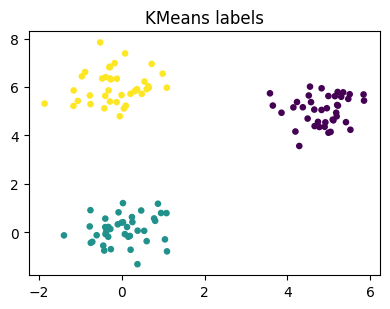

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(4, 3.2))
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=14)
plt.title('KMeans labels')
plt.tight_layout()
plt.show()